# Is there a measurable correspondence between what members of the Løgting say and how they vote?

**Methods: TF-IDF and PPMI** (week 6), comparing the text of speeches.

**Decisions so far:**
- Both periods together: we do **not** split before / after the election (8 Dec 2022). All speeches up to 4 May 2023 are used as one set.

## Step 1: load and clean the data

**Rule:** we never change the shared data files. We filter in this notebook and write down **how many rows** each filter removes (table in 1f).

**Cleaning vs choosing:**
- **Cleaning** = removing things that are wrong or not real data (errors, empty values, non-debate text). Done here.
- **Choosing** = decisions about what to study (minimum words, Blankt votes, short "takk fyri" segments …). Done later, when we need them, and each one is listed as a decision.

In [1]:
import pandas as pd, numpy as np
D = '../data/'
votes   = pd.read_parquet(D + 'votes_2020-2023.parquet')
ballots = pd.read_parquet(D + 'ballots_2020-2023.parquet')
members = pd.read_parquet(D + 'members_2020-2023.parquet')
speech  = pd.read_parquet(D + 'fpsc/fpsc_train_metadata.parquet',
                          columns=['mp_id', 'name', 'date', 'contribution_type', 'topic', 'duration', 'text'])
speech['date'] = pd.to_datetime(speech['date'])
votes['meeting_date'] = pd.to_datetime(votes['meeting_date'])

print(f'{len(votes):,} votes (atkvøðugreiðslur) | {len(ballots):,} ballots (one member, one vote) | {len(members)} members')
print(f'{len(speech):,} speech segments, {speech["date"].min():%d %b %Y} to {speech["date"].max():%d %b %Y}')

1,125 votes (atkvøðugreiðslur) | 31,085 ballots (one member, one vote) | 68 members
48,028 speech segments, 29 Jul 2020 to 04 May 2023


### 1a. Ballots: what values does a vote have?

In [2]:
ballots['vote'].value_counts(dropna=False).rename('ballots')

vote
Fyri      23192
Ímóti      7391
Blankt      269
            233
Name: ballots, dtype: int64

Fyri, Ímóti and Blankt are real votes. **233 ballots are empty** (no vote recorded), so they are not data. → **removed (cleaning)**.

*Blankt is a real choice, so it stays for now. Whether to use it is a later decision.*

### 1b. Ballots: a member called "Feilur Feilur"?

In [3]:
members[members['name'].str.contains('Feilur')]

,actor_id,mp_id,name,parties,n_ballots
66,185,MPID000185,Feilur Feilur,Framsókn,8


*Feilur* means "error". This is a placeholder from the Løgting website, not a real member, with 8 ballots. → **removed (cleaning)**.

### 1c. Speeches: who is speaking?

In [4]:
speech.groupby('contribution_type').agg(segments=('text', 'size'),
                                        average_words=('text', lambda t: round(t.str.split().str.len().mean())))

,segments,average_words
contribution_type,,
chairman,24006,30
remark,9362,138
speaker,14660,392


In [5]:
print('Most common chairman segments:')
speech.loc[speech['contribution_type'] == 'chairman', 'text'].value_counts().head(6)

Most common chairman segments:


text
takk fyri                   433
ja takk                     152
ja                          129
takk fyri harra formaður    109
ger so væl                   41
takk                         34
Name: count, dtype: int64

- **speaker** = a member's speech from the rostrum (røða).
- **remark** = a short reply (stuttmerking).
- **chairman** = the chair (formaður) running the meeting: "ja takk fyri", calling the next name. That is not debate. → **removed (cleaning)**.

**Nobody disappears:** the chair is the formaður and the deputy chairs (varaformenn). Only their chair lines are removed; their own speeches and remarks (the `speaker` and `remark` columns in the table below) are kept.

**Who is chairing?** Segments per person, by type (only people with chair segments):

In [6]:
who = speech.pivot_table(index='name', columns='contribution_type', values='text', aggfunc='size').fillna(0).astype(int)
who[who['chairman'] > 0].sort_values('chairman', ascending=False)

contribution_type,chairman,remark,speaker
name,,,
Jógvan á Lakjuni,11004,2,13
Johan Dahl,3993,70,302
Bjørt Samuelsen,3572,587,575
Eyðgunn Samuelsen,3020,228,243
Heðin Mortensen,982,34,46
Jóhannis Joensen,834,601,373
Elsebeth Mercedis Gunnleygsdóttur,600,204,319
Steffan Klein Poulsen,1,218,462


### 1d. Speeches: empty text, duplicates, odd lengths

In [7]:
deb = speech[speech['contribution_type'] != 'chairman'].copy()
deb['words'] = deb['text'].fillna('').str.split().str.len()
deb['words per second'] = deb['words'] / deb['duration']
print('missing speaker id:', deb['mp_id'].isna().sum())
print('empty text:        ', (deb['words'] == 0).sum())
print('duplicates:        ', deb.duplicated(['mp_id', 'date', 'text']).sum())
print()
print('Words per second (normal speech is about 2-3):')
print(deb['words per second'].describe().round(2).to_string())
print()
print('The 5 longest segments:')
deb.nlargest(5, 'words')[['name', 'date', 'contribution_type', 'words', 'words per second']]

missing speaker id: 0
empty text:         0
duplicates:         0

Words per second (normal speech is about 2-3):
count    24022.00
mean         2.74
std          0.46
min          0.03
25%          2.44
50%          2.75
75%          3.05
max          6.00

The 5 longest segments:


,name,date,contribution_type,words,words per second
1,Bárður á Steig Nielsen,2020-07-29,speaker,3706,1.826516
38722,Bárður á Steig Nielsen,2022-07-29,speaker,3257,1.723280
21446,Bárður á Steig Nielsen,2021-07-29,speaker,3094,1.893513
43998,Dennis Holm,2023-03-14,speaker,2931,3.043614
38751,Aksel Vilhelmson Johannesen,2022-08-02,speaker,2857,3.081985


No missing speakers, no empty text and no duplicates once the chair is removed.

**Speed:** almost all segments are 2-3 words per second, which is normal speech. **71 segments** are slower than 1 word per second, but they are tiny (1-7 words, e.g. *øh*, *ger so væl*), with mostly silence in the recording. Harmless, and they are handled later by the choice about short segments.

**The longest segments are real:** the prime minister's (løgmaður) yearly opening speech (løgmansrøðan, 29 July) and the big opening debates.

→ **nothing removed**.

### 1e. Speakers who are not in the vote data

In [8]:
not_in_votes = sorted(set(deb['mp_id']) - set(ballots['mp_id']))
deb[deb['mp_id'].isin(not_in_votes)].groupby(['mp_id', 'name']).size().rename('segments')

mp_id       name                 
MPID000057  Lene Moyell  Johansen     1
MPID000172  Margit Stórá             25
MPID000184  Dennis Holm              48
Name: segments, dtype: int64

Three people speak but have **no ballots** in our vote data (e.g. they spoke as ministers without being voting members in this period). Their speeches can't be compared with votes. → **kept in the data** (they still count as text, e.g. for PPMI), but they drop out automatically when speeches are matched with votes.

### 1f. Apply the cleaning

In [9]:
clean_ballots = ballots[(ballots['vote'] != '') & (ballots['name'] != 'Feilur Feilur')].copy()
clean_speech  = deb                                   # chair already removed in 1d

log = pd.DataFrame([
    ['ballots', 'empty vote',              (ballots['vote'] == '').sum()],
    ['ballots', '"Feilur Feilur" (error)', (ballots['name'] == 'Feilur Feilur').sum()],
    ['speech',  'chair (formaður)',        (speech['contribution_type'] == 'chairman').sum()],
    ['speech',  'empty / duplicate',       0],
], columns=['data', 'removed because', 'rows'])
display(log)
print(f'Left: {len(clean_ballots):,} of {len(ballots):,} ballots | {len(clean_speech):,} of {len(speech):,} speech segments')

,data,removed because,rows
0,ballots,empty vote,233
1,ballots,"""Feilur Feilur"" (error)",8
2,speech,chair (formaður),24006
3,speech,empty / duplicate,0


Left: 30,844 of 31,085 ballots | 24,022 of 48,028 speech segments


## Step 2: one document = one member's speech in one debate, with their vote

**Document** = everything one member said about one case (mál), joined into one text.
**Vote** = how that member voted on **the proposal itself** in the **final** vote on that case. Not an amendment.

### 2a. Which votes are on the proposal itself?

A case gets several votes. We sort them by their title:

In [10]:
title = votes['vote_title'].str.lower().str.strip()
votes['kind'] = np.select(
    [title.str.match(r'(uppru|uppskot|frumrit|soleiðis)'),         # upprunauppskot(ið), uppskotið (soleiðis broytt) …
     title.str.contains(r'broyt\w*uppskot|broytungaruppskot'),     # broytingaruppskot (also misspelled)
     title.str.startswith('frávik'),
     title.str.startswith('umbiðið')],
    ['proposal itself', 'amendment', 'procedure: frávik', 'procedure: back to committee'],
    default='other')
votes['kind'].value_counts().rename('votes')

kind
proposal itself                 754
amendment                       275
procedure: frávik                54
procedure: back to committee     42
Name: votes, dtype: int64

- **proposal itself** = upprunauppskot / uppskotið (soleiðis broytt): yes or no to the whole case. ← **we use these**
- **amendment** (broytingaruppskot) = a small change to the proposal.
- **frávik** = permission to skip a rule about deadlines in the procedure (tingskipanin). **back to committee** = sending the case back to the committee (nevnd).

Check the leftover "other" votes:

In [11]:
votes.loc[votes['kind'] == 'other', 'vote_title'].value_counts()

Series([], Name: count, dtype: int64)

### 2b. The final vote on the proposal, per case

The last one by **date**, then by **reading** (3. viðgerð after 2. viðgerð). On the same day, the 2nd and 3rd reading can both happen.

In [12]:
votes['reading'] = votes['stage'].str.extract(r'(\d)\.', expand=False).astype(float)
final = (votes[votes['kind'] == 'proposal itself']
         .sort_values(['meeting_date', 'reading', 'vote_id'])
         .groupby('case_number').tail(1)
         .set_index('case_number'))
print(f"{votes['case_number'].nunique()} cases have votes | {len(final)} have a vote on the proposal itself")
print()
print('Reading of the final vote:')
print(final['stage'].value_counts().to_string())

459 cases have votes | 456 have a vote on the proposal itself

Reading of the final vote:
stage
3. viðgerð    298
2. viðgerð    158


Example, the fishing law (sjófeingislógin) **LM-056/2020**: seven votes on the same day (16 Dec 2020). Two are on the proposal itself (2nd and 3rd reading); the final one is the 3rd reading.

In [13]:
votes.loc[votes['case_number'] == 'LM-056/2020', ['vote_id', 'meeting_date', 'stage', 'vote_title', 'kind', 'n_for', 'n_against']]

,vote_id,meeting_date,stage,vote_title,kind,n_for,n_against
145,6988,2020-12-16,3. viðgerð,Frávik,procedure: frávik,31.0,0.0
146,6946,2020-12-16,2. viðgerð,Broytingaruppskot frá minnilutanum í Vinnunevn...,amendment,31.0,0.0
147,6938,2020-12-16,2. viðgerð,Upprunauppskot soleiðis broytt,proposal itself,17.0,14.0
148,6953,2020-12-16,3. viðgerð,Broytingaruppskot 1,amendment,14.0,17.0
149,6954,2020-12-16,3. viðgerð,Broytingaruppskot 2,amendment,24.0,0.0
150,6955,2020-12-16,3. viðgerð,Broytingaruppskot 3,amendment,14.0,17.0
151,6948,2020-12-16,3. viðgerð,"Upprunauppskot, sum samtykt við 2. viðgerð og ...",proposal itself,17.0,14.0


### 2c. Which case is each speech about?

The `topic` of a speech segment names the case, e.g. *"… 3. viðgerð av LM-056/2020 …"*. We pull out the case number.

In [14]:
clean_speech['case_number'] = clean_speech['topic'].str.extract(r'((?:LM|FG)-\d{3}/\d{4})', expand=False)
has_case = clean_speech['case_number'].notna()
print(f'{has_case.sum():,} of {len(clean_speech):,} segments ({has_case.mean():.0%}) name a case')
print()
print('Examples of topics WITHOUT a case number:')
clean_speech.loc[~has_case, 'topic'].str[:90].value_counts().head(6)

20,129 of 24,022 segments (84%) name a case

Examples of topics WITHOUT a case number:


topic
Uppskot til samtyktar viðvíkjandi rættinum hjá føroyingum at ganga í haga                    226
Aðalorðaskifti sambært § 51, stk. 4 í Tingskipaninium F-002/2020: Frágreiðing um alivinnun    108
Tikið av dagskrá:                                                                             101
Umrøða av spurningi SS-002/2020  Endurskoðan av lærugreinabýtinum í fólkaskúlanum              90
Umrøða av spurningi SS-003/2020  Rúsevni                                                       71
Umrøða av spurningi SS-003/2022  Oljuleiting í føroyskum øki                                   68
Name: count, dtype: int64

### 2d. Build the documents and attach the vote

In [15]:
docs = (clean_speech[has_case]
        .groupby(['mp_id', 'case_number'])
        .agg(name=('name', 'first'), date=('date', 'min'), segments=('text', 'size'),
             words=('words', 'sum'), text=('text', ' '.join))
        .reset_index())

docs['final_vote_id'] = docs['case_number'].map(final['vote_id'])
fb = clean_ballots[['vote_id', 'mp_id', 'vote', 'party']].rename(columns={'vote_id': 'final_vote_id'})
docs = docs.merge(fb, on=['final_vote_id', 'mp_id'], how='left')

no_final = docs['final_vote_id'].isna()
no_ballot = ~no_final & docs['vote'].isna()
log2 = pd.DataFrame([
    ['documents (member + case)',                         len(docs)],
    ['… case has no final vote on the proposal',            no_final.sum()],
    ['… member did not vote in that final vote',            no_ballot.sum()],
    ['documents WITH a vote',                              docs['vote'].notna().sum()],
], columns=['', 'documents'])
log2

,,documents
0,documents (member + case),4509
1,… case has no final vote on the proposal,412
2,… member did not vote in that final vote,953
3,documents WITH a vote,3144


In [16]:
print('Votes in the documents that have one:')
docs['vote'].value_counts().rename('documents')

Votes in the documents that have one:


vote
Fyri      2240
Ímóti      851
Blankt      53
Name: documents, dtype: int64

Example, the fishing law **LM-056/2020**: each member who spoke, how much, and how they voted on the proposal itself.

In [17]:
docs.loc[docs['case_number'] == 'LM-056/2020', ['name', 'party', 'segments', 'words', 'vote']].sort_values('vote').style.hide(axis='index')   # hide the row numbers

name,party,segments,words,vote
Beinir Johannesen,Fólkaflokkurin,6,1870,Fyri
Edva Jacobsen,Sambandsflokkurin,6,1071,Fyri
Johan Dahl,Sambandsflokkurin,14,4619,Fyri
Frimodt Rasmussen,Sambandsflokkurin,1,113,Fyri
Jóhan Eli Poulsen,Fólkaflokkurin,4,542,Fyri
Bill Justinussen,Miðflokkurin,8,2398,Fyri
Jákup Mikkelsen,Fólkaflokkurin,6,1882,Fyri
Christian Andreasen,Fólkaflokkurin,1,51,Fyri
Jógvan á Lakjuni,Fólkaflokkurin,6,877,Fyri
Uni Rasmussen,Fólkaflokkurin,2,208,Fyri


**Why the proposal itself matters:** on amendments 1 and 3 (3rd reading, same day) the votes were **reversed**: everyone who voted Fyri on the law voted Ímóti on them, and the other way round. E.g. Høgni Hoydal (against the law) voted Fyri on them, Johan Dahl (for the law) voted Ímóti. Had we used those amendments, every label would be flipped.

**NaN** = the member spoke in the debate but was not in the final vote.

### 2e. Speeches without a vote

In [18]:
missing = docs[docs['final_vote_id'].notna() & docs['vote'].isna()].copy()
final_date = missing['case_number'].map(final['meeting_date'])

# did the member vote in any other vote that day?
day = clean_ballots.merge(votes[['vote_id', 'meeting_date']], on='vote_id')
voted_on = set(zip(day['mp_id'], day['meeting_date']))
missing['voted that day'] = [(m, d) in voted_on for m, d in zip(missing['mp_id'], final_date)]

# did the member vote on the same proposal at an earlier reading?
pv = votes.loc[votes['kind'] == 'proposal itself', ['vote_id', 'case_number']].merge(clean_ballots[['vote_id', 'mp_id']], on='vote_id')
earlier = set(zip(pv['mp_id'], pv['case_number']))
missing['earlier vote'] = [(m, c) in earlier for m, c in zip(missing['mp_id'], missing['case_number'])]

print(f"{len(missing)} of {docs['final_vote_id'].notna().sum()} documents on a voted case have no vote from the member")
pd.DataFrame({'documents': [(~missing['voted that day']).sum(), missing['voted that day'].sum(), missing['earlier vote'].sum()]},
             index=['no vote at all that day (away, or no longer a member)',
                    'voted that day, but not in this final vote',
                    'of all: voted on the same proposal at an earlier reading'])

953 of 4097 documents on a voted case have no vote from the member


,documents
"no vote at all that day (away, or no longer a member)",624
"voted that day, but not in this final vote",329
of all: voted on the same proposal at an earlier reading,201


<div style="background-color:rgba(232,89,12,0.15); border-left:5px solid #e8590c; padding:10px 14px;">

**⚠️ Limitation: speeches without a vote are left out**

About 1 in 4 documents on a voted case (953 of 4,097, about 1.2 million words) have no vote from the member, so they are not part of the speech vs vote comparison. Our results are only about members who **were there and voted**.

The **329** who voted that day but not on this case may have **stayed out on purpose**, e.g. to avoid voting against their own party. If so, we leave out exactly the cases where speech and vote might **not** match, and our results may look more like "they vote as they speak" than reality.

*Possible later check: use the earlier-reading vote (201 documents), or look at the 329 by hand.*

</div>

## Step 3: TF-IDF

**Choice:** only **Fyri** and **Ímóti** documents. Blankt (53 documents) is left out: too few, and not a clear side.

In [19]:
fi = docs[docs['vote'].isin(['Fyri', 'Ímóti'])].reset_index(drop=True)
print(f"{len(fi):,} documents | Fyri {(fi['vote'] == 'Fyri').sum():,} | Ímóti {(fi['vote'] == 'Ímóti').sum():,}")
print(f"{fi['case_number'].nunique()} cases | {fi['mp_id'].nunique()} members")

3,091 documents | Fyri 2,240 | Ímóti 851
305 cases | 62 members


### 3a. Remove names

Members say each other's names (*"Høgni Hoydal sigur …"*). Two speeches can then look alike just because they reply to the same person. So we remove names, as the course does.

**How:** take every part of every name in the member list and the speech data. Also remove words that **contain a surname** (6+ letters), because speech-to-text often glues names together (*billjustinussen*, *siristenberg*).

**Not removed:** name parts that are also ordinary words or places: *í, á, av, hans, grund, rósa, kristin* (Christian, as in the religion), *sandoy* (the island) and *feilur* (error).

In [20]:
import re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

PATTERN = r'(?u)\b[^\W\d_]{2,}\b'                        # letters only, at least 2
NOT_NAMES = {'í', 'á', 'av', 'e', 'j', 'hans', 'grund', 'rósa', 'kristin', 'sandoy', 'feilur'}

all_names = set(members['name']) | set(speech['name'].dropna())
name_parts = {t for n in all_names for t in re.findall(r'[^\W\d_]+', n.lower())} - NOT_NAMES
surnames = {n.lower().split()[-1] for n in all_names} - NOT_NAMES
surnames = {s for s in surnames if len(s) >= 6}

vocab = CountVectorizer(token_pattern=PATTERN).fit(fi['text']).get_feature_names_out()
name_words = sorted(w for w in vocab if w in name_parts or any(s in w for s in surnames))
print(f'{len(name_words)} name words removed, e.g.:')
print(', '.join(name_words[::8]))

563 name words removed, e.g.:
abrahamsen, akseljohannesen, andreasen, andreasentakkfyrihara, areynatúgvum, beinir, biljustinussensen, bjahammer, bjohannesen, bljustinussensum, bæðifimonsrasmussen, djóni, edvajacobsentakk, erardjoensen, eyðgunn, fyrbiljustinussengersætakk, fyrikalijohannesen, gniclasen, hammerfis, hammersa, heginmortensen, hnhammer, hoydald, hoydaln, hristanandreasen, háfossum, ingilín, jacobsensum, jajaudmikkelsen, jakuvestergaard, jensenrasmussja, joensenbjørt, joensengesætakk, joensenm, joensentakkfyra, johannesenger, johannesensum, johansens, jákupsstovu, jørginiclasen, khøgnihoydal, klepoulsen, kristinaháfoss, larsløkkurasmussen, magnsrasmussen, mikkelsenar, mikkelsennevndi, niclasenini, old, petersenes, polareynatúgvu, poulsengersvætakk, poulsensvæltakfyri, pálsdóttir, rasmussenger, rasmussens, rasteinielsenja, ruth, samuelsens, siristenbergtakk, sirurstenberg, siðurstenberg, steffan, stenbergger, sumsiristenberg, sólheim, tenrasmussenger, tykursyndháfoss, varniel

### 3b. Turn each document into a TF-IDF vector

**TF-IDF** gives every word in a document a score:
- **TF** (term frequency): how often the word is used **in this document**. High = the speaker talks about it a lot.
- **IDF** (inverse document frequency): how **rare** the word is across **all** documents. Words everyone uses (*og, at, tað*) get almost nothing.
- **TF × IDF**: high for words that are typical for **this** speech and not for all speeches.

| Setting | Value | Meaning |
|---|---|---|
| words | letters only, at least 2 | numbers and single letters are skipped |
| `min_df` | 3 | a word must be used in at least 3 documents (drops typos and speech-to-text errors) |
| `max_df` | 0.5 | a word used in more than half of all documents is dropped (*og, at, tað* …) |
| `sublinear_tf` | True | count 1 + log(count): saying a word 20 times does not count 20× as much as once |

In [21]:

tfidf = TfidfVectorizer(lowercase=True, token_pattern=PATTERN,
                        min_df=3, max_df=0.5, sublinear_tf=True,
                        stop_words=name_words)        # names removed (3a)
X = tfidf.fit_transform(fi['text'])
words = tfidf.get_feature_names_out()
print(f'{X.shape[0]:,} documents x {X.shape[1]:,} words')

3,091 documents x 31,796 words


### 3c. Check: the top TF-IDF words of a few speeches

If TF-IDF works, the top words should say **what the speech is about**. Example: **a shorter work week** (stytta arbeiðsvikuna), **LM-021/2021**: the 3 longest speeches on each side.

In [22]:
def top_words(row, k=12):
    v = X[row].toarray().ravel()
    best = v.argsort()[::-1][:k]
    return ', '.join(words[best])

ex = (fi[fi['case_number'] == 'LM-021/2021']
      .sort_values('words', ascending=False)
      .groupby('vote').head(3)                       # 3 longest speeches per side
      .sort_values(['vote', 'words'], ascending=[True, False]))
print(votes.loc[votes['case_number'] == 'LM-021/2021', 'case_title'].iloc[0])
pd.DataFrame({'member': ex['name'], 'party': ex['party'], 'vote': ex['vote'], 'words spoken': ex['words'],
              'top TF-IDF words': [top_words(r) for r in ex.index]}).style.hide(axis='index')

Uppskot til samtyktar um at stytta arbeiðsvikuna


member,party,vote,words spoken,top TF-IDF words
Ingilín Didriksen Strøm,Javnaðarflokkurin,Fyri,4950,"arbeiðsvikuna, arbeiðsvikan, arbeiðstíðini, stytta, arbeiðsvika, afturvíst, arbeiðsviku, stytt, sjeyogtretivu, tímar, fakfeløg, stytting"
Aksel Vilhelmson Johannesen,Javnaðarflokkurin,Fyri,4796,"arbeiðsvikuna, stytta, sjeyogtretivu, stitta, tímar, tímum, arbeiðsvikan, stytt, arbeiðslív, familjulív, aðrastaðnis, arbeiðsviku"
Eyðgunn Samuelsen,Javnaðarflokkurin,Fyri,2261,"arbeiðstíðin, familjulív, kanningini, arbeiðs, fakfeløgini, niðursett, arbeiðslív, arbeiðslívið, familjulívi, partarnar, lokkandi, arbeiðsmarknaðini"
Ruth Vang,Framsókn,Ímóti,1689,"niðursetta, arbeiðsvikuna, stytta, kvinnur, kvinnan, útrokningina, átekur, strongd, vaktum, tilgongd, pástandur, fulla"
Edva Jacobsen,Sambandsflokkurin,Ímóti,1542,"tímar, sjeyogtretivu, náttarvakt, vinklar, arbeiðsmarknaði, fjøruti, løn, opin, arbeiðir, geri, vælskrá, herda"
Christian Andreasen,Fólkaflokkurin,Ímóti,1525,"arbeiðsvikuna, stytta, fakfeløgini, effektivitetin, tímar, arbeiðsmarknaðinum, miliónur, samráðingum, fakfeløgin, fakfeløgunum, arbeiðsvikan, arbeiðsviku"


**What we see:** everyone shares the topic words (*arbeiðsvikuna, stytta, tímar*). The Fyri side talks about **life** (*familjulív, arbeiðslív*), the Ímóti side about **cost and practice** (*løn, miliónur, effektivitetin, náttarvakt*).

**A speech that does not match the vote:** Ruth Vang voted **Ímóti**, but says she is *"sannførd um at tað eru nógvir fyrimunir við at stytta arbeiðsvikuna"* (convinced there are many advantages), and talks about women, stress and shifts. She doubts the **calculation** (*útrokningina*) behind the proposal. TF-IDF only shows **what** she talks about, not whether she is for or against. → a case to read by hand.

### 3d. The TF-IDF table

**One row per member per debate**: everything that member said on that case (all their speeches and remarks, joined). **One column per word**. Each cell = that word's TF-IDF score in that row. **0** = the word is not used.

Below: 6 members on the shorter work week (LM-021/2021) and a few chosen words. Step 4 compares these **rows** with cosine.

In [23]:
print(f'{X.shape[0]:,} rows (documents) x {X.shape[1]:,} columns (words)')
print(f'{X.nnz / (X.shape[0] * X.shape[1]):.1%} of the cells are not 0  ("sparse": almost all cells are 0)')

rows = fi.index[(fi['case_number'] == 'LM-021/2021')]
rows = fi.loc[rows].sort_values('words', ascending=False).groupby('vote').head(3).sort_values(['vote', 'words'], ascending=[True, False]).index
cols = ['arbeiðsvikuna', 'stytta', 'tímar', 'familjulív', 'arbeiðslív', 'løn', 'miliónur', 'effektivitetin', 'fiskidagar']
col_idx = [list(words).index(w) for w in cols]
pd.DataFrame(X[rows][:, col_idx].toarray().round(3), columns=cols,
             index=[f"{fi.loc[r, 'name']} ({fi.loc[r, 'vote']})" for r in rows])

3,091 rows (documents) x 31,796 columns (words)
0.9% of the cells are not 0  ("sparse": almost all cells are 0)


,arbeiðsvikuna,stytta,tímar,familjulív,arbeiðslív,løn,miliónur,effektivitetin,fiskidagar
Ingilín Didriksen Strøm (Fyri),0.110,0.102,0.085,0.072,0.049,0.057,0.000,0.036,0.0
Aksel Vilhelmson Johannesen (Fyri),0.117,0.099,0.093,0.086,0.087,0.070,0.000,0.000,0.0
Eyðgunn Samuelsen (Fyri),0.085,0.066,0.073,0.117,0.098,0.061,0.000,0.000,0.0
Ruth Vang (Ímóti),0.154,0.128,0.058,0.054,0.052,0.055,0.000,0.000,0.0
Edva Jacobsen (Ímóti),0.053,0.051,0.153,0.000,0.000,0.089,0.000,0.000,0.0
Christian Andreasen (Ímóti),0.160,0.139,0.114,0.000,0.000,0.000,0.108,0.114,0.0


## Step 4: do members who voted the same use more similar words?

Take one debate. **Example:** the shorter work week (LM-021/2021), shown in 4a.

- **Compare every pair** of members with **cosine similarity** → a cosine matrix.
  Cosine compares two rows of the TF-IDF table (3d) by the **angle** between them: **1** = the same words in the same proportions, **0** = no words in common. Only the mix of words counts, not how much was said.
- **Split the pairs into two piles** by how they voted:
  - *same vote*: Fyri–Fyri or Ímóti–Ímóti
  - *different vote*: Fyri–Ímóti
- **Gap** = average of *same* − average of *different*.
  In the example: 0.132 − 0.125 = **+0.007**

**Then** do this for every debate (with at least 2 Fyri and 2 Ímóti) and average the gaps.

**Reading it:** gap clearly above 0 → members who vote alike also talk alike. Gap ≈ 0 → we can't see it in their words.
*Why inside one debate?* Everyone talks about the same case, so a difference comes from **how** they talk, not **what** they talk about.

### 4a. One debate: the shorter work week (LM-021/2021)

The same 6 speeches as in the TF-IDF table above (3 longest on each side). Each cell = cosine similarity of two rows of X: **1** = identical word use, **0** = no words in common.

In [24]:
from sklearn.metrics.pairwise import cosine_similarity

six = fi.loc[rows]                                   # the same 6 speeches as in the TF-IDF table (3b)
S6 = pd.DataFrame(cosine_similarity(X[six.index]).round(2),
                  index=[f"{n} ({v})" for n, v in zip(six['name'], six['vote'])],
                  columns=[n.split()[0] for n in six['name']])
S6

,Ingilín,Aksel,Eyðgunn,Ruth,Edva,Christian
Ingilín Didriksen Strøm (Fyri),1.00,0.40,0.33,0.29,0.20,0.27
Aksel Vilhelmson Johannesen (Fyri),0.40,1.00,0.29,0.25,0.20,0.24
Eyðgunn Samuelsen (Fyri),0.33,0.29,1.00,0.26,0.15,0.17
Ruth Vang (Ímóti),0.29,0.25,0.26,1.00,0.14,0.17
Edva Jacobsen (Ímóti),0.20,0.20,0.15,0.14,1.00,0.13
Christian Andreasen (Ímóti),0.27,0.24,0.17,0.17,0.13,1.00


In [25]:
# the gap, using ALL speakers in this debate (not just the 6)
one = fi[fi['case_number'] == 'LM-021/2021']
S = cosine_similarity(X[one.index])
v = one['vote'].to_numpy()
same, diff = [], []
for i in range(len(v)):
    for j in range(i + 1, len(v)):
        (same if v[i] == v[j] else diff).append(S[i, j])
print(f'All {len(v)} speakers ({(v == "Fyri").sum()} Fyri, {(v == "Ímóti").sum()} Ímóti):')
print(f'same-vote pairs:      {len(same):3}  average similarity {np.mean(same):.3f}')
print(f'different-vote pairs: {len(diff):3}  average similarity {np.mean(diff):.3f}')
print(f'gap: {np.mean(same) - np.mean(diff):+.3f}')

All 20 speakers (9 Fyri, 11 Ímóti):
same-vote pairs:       91  average similarity 0.132
different-vote pairs:  99  average similarity 0.125
gap: +0.007


### 4b. All debates

In [26]:
def debate_gaps(votes_array):
    """Gap (same − different) for every debate with at least 2 speakers on each side."""
    gaps = {}
    for case, pos in groups.items():
        v = votes_array[pos]
        if (v == 'Fyri').sum() < 2 or (v == 'Ímóti').sum() < 2:
            continue
        S = sims[case]
        iu = np.triu_indices(len(pos), 1)
        same_pair = (v[:, None] == v[None, :])[iu]
        gaps[case] = S[iu][same_pair].mean() - S[iu][~same_pair].mean()
    return pd.Series(gaps)

groups = fi.groupby('case_number').indices                       # row numbers of each debate
sims = {case: cosine_similarity(X[pos]) for case, pos in groups.items()}
real = debate_gaps(fi['vote'].to_numpy())
print(f'{len(real)} debates with at least 2 Fyri and 2 Ímóti speakers')
print(f'average gap: {real.mean():+.4f}   (debates with gap > 0: {(real > 0).mean():.0%})')

133 debates with at least 2 Fyri and 2 Ímóti speakers
average gap: +0.0011   (debates with gap > 0: 54%)


**Each debate gets its own piles and its own gap.** Then we average the gaps, so each debate counts once. Three examples:

In [27]:
show = {'LM-021/2021': 'Shorter work week', 'LM-056/2020': 'Fishing law', 'LM-016/2021': 'Budget 2022'}
rows4 = []
for case, label in show.items():
    pos = groups[case]; v = fi['vote'].to_numpy()[pos]
    iu = np.triu_indices(len(pos), 1)
    same_pair = (v[:, None] == v[None, :])[iu]
    s = sims[case][iu]
    rows4.append([label, f'{s[same_pair].mean():.3f}', f'{s[~same_pair].mean():.3f}', f'{real[case]:+.3f}'])
rows4.append([f'Average of all {len(real)} debates', '', '', f'{real.mean():+.4f}'])
pd.DataFrame(rows4, columns=['debate', 'same pile', 'different pile', 'gap']).style.hide(axis='index')

debate,same pile,different pile,gap
Shorter work week,0.132,0.125,+0.007
Fishing law,0.082,0.086,-0.004
Budget 2022,0.186,0.184,+0.002
Average of all 133 debates,,,+0.0011


### 4c. Is the gap bigger than chance?

Shuffle the votes **inside each debate** (same number of Fyri and Ímóti), compute the average gap again, 1,000 times. If votes have nothing to do with speech, the real gap looks like a shuffled one.

In [28]:
rng = np.random.default_rng(1)
vote_array = fi['vote'].to_numpy()
shuffled = []
for _ in range(1000):
    v = vote_array.copy()
    for pos in groups.values():
        v[pos] = rng.permutation(v[pos])
    shuffled.append(debate_gaps(v).mean())
shuffled = np.array(shuffled)
p_value = (shuffled >= real.mean()).mean()
print(f'real gap {real.mean():+.4f} | shuffled: average {shuffled.mean():+.4f}, 95% of them below {np.percentile(shuffled, 95):+.4f}')
print(f'p = {p_value:.3f}  (share of shuffles with a gap at least as big as the real one)')

real gap +0.0011 | shuffled: average +0.0000, 95% of them below +0.0025
p = 0.226  (share of shuffles with a gap at least as big as the real one)


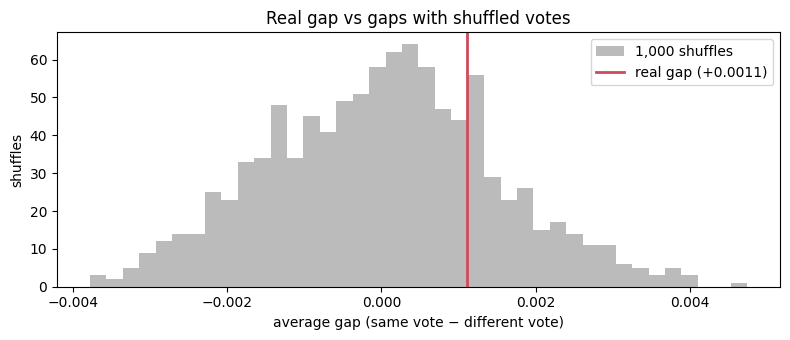

In [29]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(shuffled, bins=40, color='#bbbbbb', label='1,000 shuffles')
ax.axvline(real.mean(), color='#d1495b', lw=2, label=f'real gap ({real.mean():+.4f})')
ax.set_xlabel('average gap (same vote − different vote)'); ax.set_ylabel('shuffles'); ax.legend()
ax.set_title('Real gap vs gaps with shuffled votes'); plt.tight_layout(); plt.show()

### 4d. Niðurstøða (conclusion)

Inside the same debate, members who voted the **same** do **not** use measurably more similar words than members who voted **differently**: the average gap is **+0.0011**, and about 1 in 4 shuffles of the votes give a gap at least as big (p ≈ 0.2).

So with TF-IDF and cosine **we cannot see the vote in the words**. That does not prove members don't vote the way they speak: TF-IDF mostly sees **what** they talk about, not **for or against** (see Ruth Vang in 3c).

## Step 5: Step 4 again, with 300+ word texts only

Short texts have few words, so their cosine is noisy and may hide a real gap.

In [30]:
def gap_test(D, keep, n_shuffles=1000, seed=1):
    """Step 4 on document vectors D, only rows where keep is True:
    real average gap, and p = share of vote-shuffles with a gap at least as big."""
    vote = fi['vote'].to_numpy()
    use = {}                                                           # debate -> (rows, pair similarities, pair index)
    for case, pos in fi[keep].groupby('case_number').indices.items():
        rows_ = fi[keep].index[pos]
        v = vote[rows_]
        if (v == 'Fyri').sum() >= 2 and (v == 'Ímóti').sum() >= 2:
            iu = np.triu_indices(len(rows_), 1)
            use[case] = (rows_, cosine_similarity(D[rows_])[iu], iu)

    def mean_gap(vote):
        gaps = []
        for rows_, s, iu in use.values():
            v = vote[rows_]
            same_pair = (v[:, None] == v[None, :])[iu]
            gaps.append(s[same_pair].mean() - s[~same_pair].mean())
        return np.mean(gaps)

    real_gap = mean_gap(vote)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_shuffles):
        v = vote.copy()
        for rows_, _s, _iu in use.values():
            v[rows_] = rng.permutation(v[rows_])
        null.append(mean_gap(v))
    null = np.array(null)
    return {'documents': int(keep.sum()), 'debates': len(use), 'gap': round(real_gap, 4),
            'p (vs shuffled)': round((null >= real_gap).mean(), 3)}, null

all_rows  = np.ones(len(fi), dtype=bool)
long_rows = fi['words'].to_numpy() >= 300
res_all, null_all = gap_test(X, all_rows)
res_long, null_long = gap_test(X, long_rows)
step5 = pd.DataFrame([{'texts': 'all', **res_all}, {'texts': 'at least 300 words', **res_long}])
step5.style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'})

texts,documents,debates,gap,p (vs shuffled)
all,3091,133,+0.0011,0.20
at least 300 words,2220,122,+0.0019,0.11


**What is p?** We shuffle the votes inside each debate 1,000 times (votes then mean nothing) and compute the gap each time: the grey bars below. **p** = the share of shuffles with a gap **at least as big** as the real one (the red line). Small p (below 0.05) = the real gap is rarely reached by chance.

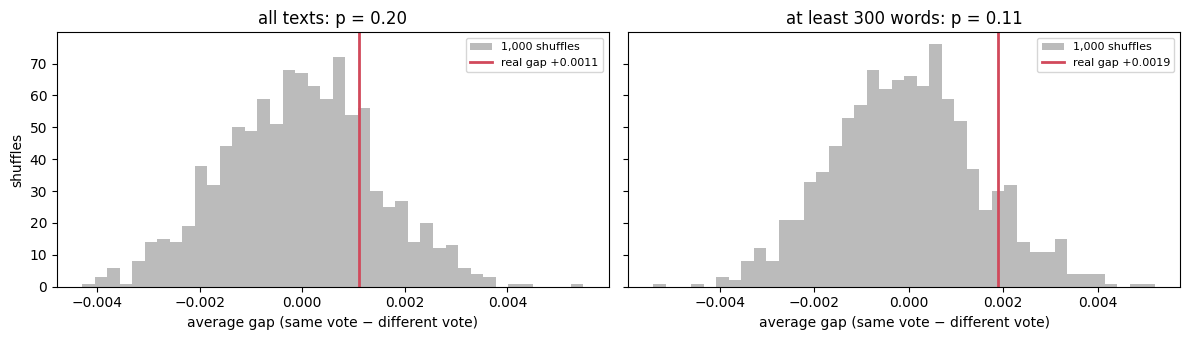

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, null, res, title in ((axes[0], null_all, res_all, 'all texts'),
                             (axes[1], null_long, res_long, 'at least 300 words')):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['gap'], color='#d1495b', lw=2, label=f"real gap {res['gap']:+.4f}")
    ax.set_title(f"{title}: p = {res['p (vs shuffled)']:.2f}")
    ax.set_xlabel('average gap (same vote − different vote)'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
plt.tight_layout(); plt.show()

### 5. Niðurstøða

With only the longer texts the gap gets a bit **bigger** (+0.0019 instead of +0.0011) and p gets **smaller** (about 0.11 instead of 0.2), so short, noisy texts did hide a little. But it is **still not clearly above chance**: about 1 in 9 shuffles give a gap at least this big. The answer stays the same: with TF-IDF and cosine we cannot clearly see the vote in the words.

*(The "all" row gives p = 0.21 here and 0.23 in 4c: both use 1,000 random shuffles, so p moves a little between runs.)*

## Step 6: PPMI (week 6)

TF-IDF only matches **exactly the same word**: *arbeiðsvikuna* and *arbeiðsvikan*, or *dýrari* and *kostar meira*, count as unrelated. **PPMI** describes each word by **the words around it**, so words used in the same way get similar vectors.

**Plan:**
- **6a.** Build PPMI word vectors from **all** cleaned speech (also speeches without a vote: PPMI only needs text). Names removed.
- **6b.** Check: the closest words of a few words.
- **6c.** Turn each text into a vector (like the Marvel map in week 6: the average of its words' vectors, weighted by TF-IDF) and do Step 4 again.

### 6a. PPMI word vectors

1. Split every speech segment into words. Keep words used at least **20 times**.
2. **Count** for every word which words appear within **4 words** left or right → the word × context table.
3. **PMI** = log( how often the pair appears together / how often it would by chance ). Keep only **positive** values → **PPMI**.
4. A word's **PPMI vector** = its row in that table.

(Standard trick: context counts are raised to the power 0.75, so very rare context words don't get huge values.)

In [32]:
from collections import Counter
from scipy import sparse
from sklearn.preprocessing import normalize

TOKEN = re.compile(r'[^\W\d_]+')
name_set = set(name_words)
sents = [[w for w in TOKEN.findall(t.lower()) if w not in name_set] for t in clean_speech['text']]
counts = Counter(w for s in sents for w in s)
ppmi_vocab = np.array(sorted(w for w, c in counts.items() if c >= 20))
ppmi_index = {w: i for i, w in enumerate(ppmi_vocab)}

pairs_r, pairs_c = [], []
for s in sents:
    ids = np.array([ppmi_index.get(w, -1) for w in s])
    for k in range(1, 5):                                     # words 1, 2, 3, 4 apart
        a, b = ids[:-k], ids[k:]
        ok_ = (a >= 0) & (b >= 0)
        pairs_r.append(a[ok_]); pairs_c.append(b[ok_])
r, c = np.concatenate(pairs_r), np.concatenate(pairs_c)
V = len(ppmi_vocab)
counts_table = sparse.coo_matrix((np.ones(len(r)), (r, c)), shape=(V, V)).tocsr()
counts_table = (counts_table + counts_table.T).tocoo()         # left and right neighbours

total = counts_table.sum()
p_word = np.asarray(counts_table.sum(axis=1)).ravel() / total
p_ctx = np.asarray(counts_table.sum(axis=0)).ravel() ** 0.75
p_ctx = p_ctx / p_ctx.sum()
pmi = np.log((counts_table.data / total) / (p_word[counts_table.row] * p_ctx[counts_table.col]))
positive = pmi > 0
PPMI = normalize(sparse.csr_matrix((pmi[positive], (counts_table.row[positive], counts_table.col[positive])), shape=(V, V)))
print(f'{sum(counts.values()):,} words spoken | {V:,} words used at least 20 times -> PPMI table {V:,} x {V:,}')

7,015,570 words spoken | 11,407 words used at least 20 times -> PPMI table 11,407 x 11,407


**A look inside the PPMI table:** one row per **word**, one column per **nearby word**. Each cell = **PPMI**: the PMI (how much more often than chance the two words appear within 4 words of each other), with values below 0 set to **0**. Compare with the TF-IDF table in 3d, where the rows are **texts**.

In [33]:
PPMI_raw = sparse.csr_matrix((pmi[positive], (counts_table.row[positive], counts_table.col[positive])), shape=(V, V))
print(f'{V:,} rows (words) x {V:,} columns (nearby words) | {PPMI_raw.nnz / V**2:.1%} of the cells are not 0')
show_rows = ['arbeiðsvikuna', 'familjulív', 'arbeiðslív', 'dýrari', 'bíligari', 'krónur']
show_cols = ['stytta', 'tímar', 'arbeiðslív', 'familjulív', 'javnvág', 'krónur', 'milliónir', 'fiskidagar']
pd.DataFrame(PPMI_raw[[ppmi_index[w] for w in show_rows]][:, [ppmi_index[w] for w in show_cols]].toarray().round(1),
             index=show_rows, columns=show_cols)

11,407 rows (words) x 11,407 columns (nearby words) | 2.3% of the cells are not 0


,stytta,tímar,arbeiðslív,familjulív,javnvág,krónur,milliónir,fiskidagar
arbeiðsvikuna,6.8,3.8,2.8,2.9,0.0,0.0,0.0,0.0
familjulív,3.4,2.4,7.8,5.3,4.6,0.0,0.0,0.0
arbeiðslív,0.0,2.4,0.0,7.8,4.6,0.0,0.0,0.0
dýrari,0.0,0.0,0.0,0.0,0.0,0.8,1.7,0.0
bíligari,0.0,0.0,0.0,0.0,0.0,0.4,0.0,0.0
krónur,0.0,0.0,0.0,0.0,0.0,1.8,3.6,0.0


### 6b. Check: the closest words (cosine between PPMI vectors)

In [34]:
def neighbours(word, k=8):
    i = ppmi_index[word]
    s = (PPMI @ PPMI[i].T).toarray().ravel()
    s[i] = -1
    return ', '.join(f'{ppmi_vocab[j]} ({s[j]:.2f})' for j in np.argsort(-s)[:k])

check = ['landsstýrið', 'arbeiðsvikuna', 'familjulív', 'dýrari', 'jalig', 'krónur']
pd.DataFrame({'word': check, 'closest words': [neighbours(w) for w in check]}).style.hide(axis='index')

word,closest words
landsstýrið,"løgtingið (0.28), landsstýri (0.26), landsstýrismaðurin (0.22), samgongan (0.20), landstýrið (0.20), heitir (0.17), landsstýrinum (0.17), mann (0.17)"
arbeiðsvikuna,"stytta (0.56), arbeiðstíðina (0.25), stytt (0.25), sjeyogtretivu (0.21), tímum (0.21), tímatalið (0.21), arbeiðsviku (0.20), arbeiðsvikan (0.20)"
familjulív,"arbeiðslív (0.41), arbeiðsmarknað (0.21), samanhang (0.16), hanga (0.15), fáa (0.15), javnrættindi (0.14), arbeiðs (0.13), sálarheilsu (0.13)"
dýrari,"bíligari (0.23), dýrt (0.18), dýrar (0.18), truplari (0.16), enn (0.16), bilar (0.15), hægri (0.15), munandi (0.14)"
jalig,"positiv (0.24), jaligur (0.21), jalið (0.18), skeptisk (0.17), kritisk (0.17), sum (0.17), jaliga (0.16), positivt (0.15)"
krónur,"milliónir (0.68), hundrað (0.66), túsund (0.57), komma (0.50), miliónir (0.46), fimm (0.45), krónum (0.45), umleið (0.44)"


- **Other forms and spellings land together** (e.g. *landsstýrið* → *landsstýri, landsstýrinum*, and *landstýrið*, a speech-to-text spelling). That is what TF-IDF cannot do.
- **⚠️ Opposites land together too** (*dýrari* → *bíligari*; *jalig* → *skeptisk, kritisk*): they are used in the same places. So PPMI closeness means **"used in the same way"**, not "same opinion".

### 6c. Texts as PPMI vectors, and Step 4 again

Each text's vector = the **average of its words' PPMI vectors, weighted by their TF-IDF score** (the same recipe as the Marvel map in week 6).

Averages of word vectors all look alike (they share the common words' contexts), so we also try a **centred** version: subtract the average text, so only what is special about each text is left.

<div style="background-color:rgba(201,185,138,0.15); border-left:5px solid #c9b98a; padding:10px 14px;">

**Example** (made up: a text of 3 words, vectors of 3 numbers). Edva's text = *tímar, løn, náttarvakt*

| word | PPMI vector (near *arbeiði*, *pengar*, *familja*) | TF-IDF weight | weight × vector |
|---|---|---|---|
| tímar | (6, 1, 2) | 0.6 | (3.6, 0.6, 1.2) |
| løn | (2, 7, 0) | 0.3 | (0.6, 2.1, 0) |
| náttarvakt | (5, 1, 1) | 0.1 | (0.5, 0.1, 0.1) |
| **text vector** (sum) | | | **(4.7, 2.8, 1.3)** |

→ mostly "near *arbeiði*", because the most important word (*tímar*) sits there. 🥤 Like a smoothie: the fruit you use most decides the taste. Marvel: Spider-Man = a mix of *web, spider, venom*.

</div>

average cosine between two texts: PPMI 0.80 | PPMI centred 0.01 | TF-IDF 0.04


vectors,documents,debates,gap,p (vs shuffled)
TF-IDF (Step 4),3091,133,+0.0011,0.20
PPMI,3091,133,-0.0010,0.65
"PPMI, centred",3091,133,-0.0122,0.85


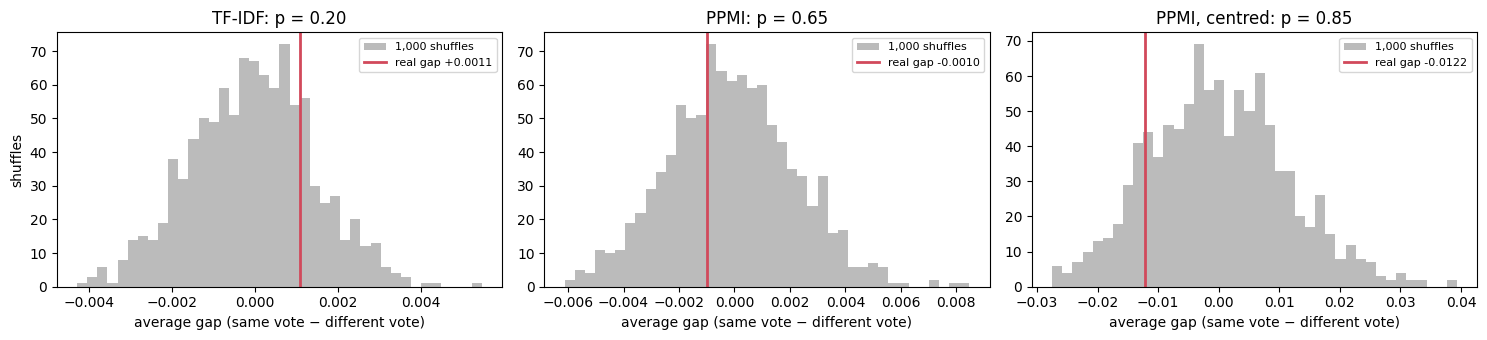

In [35]:
tfidf_index = {w: i for i, w in enumerate(words)}
common = [w for w in ppmi_vocab if w in tfidf_index]               # words in both tables
D = (X[:, [tfidf_index[w] for w in common]] @ PPMI[[ppmi_index[w] for w in common]]).tocsr()
D_centred = D.toarray()
D_centred -= D_centred.mean(axis=0)

sample = np.triu_indices(300, 1)
print(f'average cosine between two texts: PPMI {cosine_similarity(D[:300])[sample].mean():.2f} | '
      f'PPMI centred {cosine_similarity(D_centred[:300])[sample].mean():.2f} | TF-IDF {cosine_similarity(X[:300])[sample].mean():.2f}')

res6_ppmi, null6_ppmi = gap_test(D, all_rows)
res6_cent, null6_cent = gap_test(D_centred, all_rows)
step6 = pd.DataFrame([{'vectors': 'TF-IDF (Step 4)', **res_all},
                      {'vectors': 'PPMI', **res6_ppmi},
                      {'vectors': 'PPMI, centred', **res6_cent}])
display(step6.style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'}))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, null, res, title in ((axes[0], null_all, res_all, 'TF-IDF'),
                             (axes[1], null6_ppmi, res6_ppmi, 'PPMI'),
                             (axes[2], null6_cent, res6_cent, 'PPMI, centred')):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['gap'], color='#d1495b', lw=2, label=f"real gap {res['gap']:+.4f}")
    ax.set_title(f"{title}: p = {res['p (vs shuffled)']:.2f}")
    ax.set_xlabel('average gap (same vote − different vote)'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
plt.tight_layout(); plt.show()

### 6d. Remove the most common words as neighbours

Almost every word has *og, tað, at, sum, í* … as neighbours (in 90%+ of the rows of the PPMI table). Maybe those shared columns make all texts look alike. Test: remove the **100 most common words as neighbours** (columns), and do 6c again. (The arrow version is in Step 7.)

In [36]:
top100 = [w for w, _ in counts.most_common(100)]
keep_col = np.ones(V)
keep_col[[ppmi_index[w] for w in top100 if w in ppmi_index]] = 0
PPMI_nostop = normalize(PPMI_raw @ sparse.diags(keep_col))          # same table, those 100 columns set to 0
D_nostop = (X[:, [tfidf_index[w] for w in common]] @ PPMI_nostop[[ppmi_index[w] for w in common]]).tocsr()

print(f'average cosine between two texts: {cosine_similarity(D_nostop[:300])[sample].mean():.2f}  (before: 0.80)')
pd.DataFrame([{'vectors': 'PPMI (6c)', **res6_ppmi},
              {'vectors': 'PPMI, without the 100 most common neighbours', **gap_test(D_nostop, all_rows)[0]}]
             ).style.hide(axis='index').format({'gap': '{:+.4f}', 'p (vs shuffled)': '{:.2f}'})

average cosine between two texts: 0.76  (before: 0.80)


vectors,documents,debates,gap,p (vs shuffled)
PPMI (6c),3091,133,-0.0010,0.65
"PPMI, without the 100 most common neighbours",3091,133,-0.0012,0.67


### 6. Niðurstøða

PPMI does **not** show the vote either. The gap is about **0 or even below** (same-vote pairs slightly *less* alike), and most shuffles give a gap at least as big.

**Why PPMI doesn't help here:**
- Averaging word vectors makes all texts look very alike (average cosine about 0.8), so small differences drown. Removing the most common neighbours (6d) hardly changes this: a text has hundreds of words, and their average is mostly "general Løgting language".
- PPMI puts opposites close together (*dýrari ~ bíligari*), so "for" and "against" words look the same.

PPMI is still useful for **words** (6b): it finds forms, spellings and related words. But as a way of comparing **whole texts** for or against, it does no better than TF-IDF.

## Step 7: a Fyri ↔ Ímóti arrow (like the map in week 6)

*Steps 4-6 asked whether members on the same side **sound alike** (pairs), and the answer was no. Step 7 asks a different, weaker question with the same TF-IDF table: does each text **lean towards its own side**?*

In week 6, the arrow **magic − science** gave each character a score on a science ↔ magic scale. We do the same with the two sides of a vote.

**Inside each debate, for each member:**
1. **Fyri point** = the average TF-IDF row of the **other** Fyri speakers. **Ímóti point** = the same for the **other** Ímóti speakers.
2. **Arrow** = Fyri point − Ímóti point.
3. **Score** = arrow · the member's own row (dot product). Above 0 → the text leans **Fyri**, below 0 → leans **Ímóti**.

**Pairs (Step 4) vs arrow:** Step 4 asked whether a side *sounds alike*. The arrow only asks whether each text **leans towards its own side** — a side can do that even if its members argue in different ways.

<div style="background-color:rgba(201,185,138,0.15); border-left:5px solid #c9b98a; padding:10px 14px;">

**Example: "the other"**, scoring Ruth Vang (Ímóti) in the work-week debate

| | built from | Ruth included? |
|---|---|---|
| Fyri point | the 9 Fyri speakers | – |
| Ímóti point | the **other 10** Ímóti speakers | ❌ left out |

→ Otherwise her own text would help build the Ímóti point, and she would land there automatically. The arrow is rebuilt for every member.

</div>

In [37]:
def arrow_scores(G, v):
    """Leave-one-out arrow scores in one debate. G = dot products between all texts, v = votes."""
    F = (v == 'Fyri'); I = ~F
    d = np.diag(G)
    to_fyri  = (G[:, F].sum(axis=1) - d * F) / (F.sum() - F)          # average dot product with the OTHER Fyri texts
    to_imoti = (G[:, I].sum(axis=1) - d * I) / (I.sum() - I)          # ... with the OTHER Ímóti texts
    return to_fyri - to_imoti                                         # = arrow · own text

def arrow_test(D, keep, n_shuffles=1000, seed=1):
    vote = fi['vote'].to_numpy()
    use = []
    for case, pos in fi[keep].groupby('case_number').indices.items():
        rows_ = fi[keep].index[pos]
        v = vote[rows_]
        if (v == 'Fyri').sum() >= 2 and (v == 'Ímóti').sum() >= 2:
            Dr = D[rows_]
            G = Dr @ Dr.T
            use.append((rows_, G.toarray() if hasattr(G, 'toarray') else G))

    def share_on_own_side(vote):
        right = [((arrow_scores(G, vote[rows_]) > 0) == (vote[rows_] == 'Fyri')) for rows_, G in use]
        return np.concatenate(right).mean()

    real_share = share_on_own_side(vote)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_shuffles):
        v = vote.copy()
        for rows_, _G in use:
            v[rows_] = rng.permutation(v[rows_])
        null.append(share_on_own_side(v))
    null = np.array(null)
    return {'texts': sum(len(r) for r, _ in use), 'debates': len(use),
            'on own side': round(real_share, 3), 'shuffled (average)': round(null.mean(), 3),
            'p (vs shuffled)': round((null >= real_share).mean(), 3)}, null

### 7a. One debate: the shorter work week

Each member's score on the Fyri ↔ Ímóti arrow (built from the others).

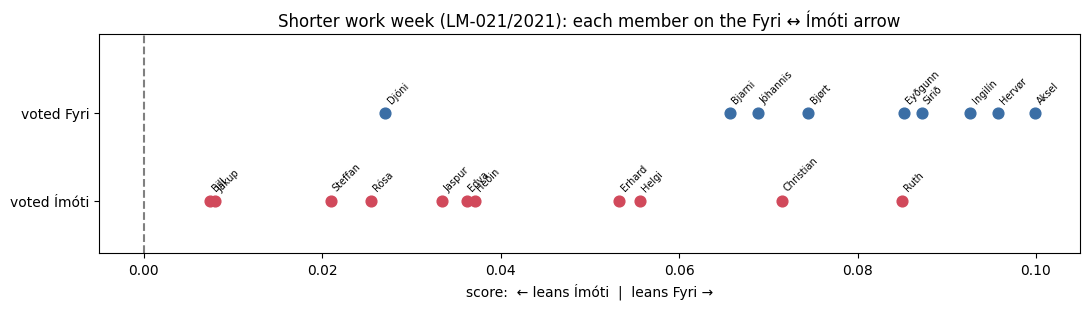

on their own side: 45% of 20 members


In [38]:
one = fi[fi['case_number'] == 'LM-021/2021']
G1 = (X[one.index] @ X[one.index].T).toarray()
sc = arrow_scores(G1, one['vote'].to_numpy())

fig, ax = plt.subplots(figsize=(11, 3.2))
for k, (side, col) in enumerate((('Ímóti', '#d1495b'), ('Fyri', '#3b6ea5'))):
    m = (one['vote'] == side).to_numpy()
    ax.scatter(sc[m], np.full(m.sum(), k), color=col, s=60, label=side)
    for x_, n_ in zip(sc[m], one['name'][m]):
        ax.annotate(n_.split()[0], (x_, k), xytext=(0, 7), textcoords='offset points', fontsize=7, rotation=45)
ax.axvline(0, color='grey', ls='--')
ax.set_yticks([0, 1]); ax.set_yticklabels(['voted Ímóti', 'voted Fyri']); ax.set_ylim(-0.6, 1.9)
ax.set_xlabel('score:  ← leans Ímóti  |  leans Fyri →')
ax.set_title('Shorter work week (LM-021/2021): each member on the Fyri ↔ Ímóti arrow')
plt.tight_layout(); plt.show()
print(f"on their own side: {((sc > 0) == (one['vote'] == 'Fyri').to_numpy()).mean():.0%} of {len(one)} members")

### 7b. All debates, and against chance

**On own side** = share of texts whose score points to the side the member actually voted. Chance should be about 50%, but to be sure we compare with **shuffled votes** again (1,000 times).

vectors,texts used,texts,debates,on own side,shuffled (average),p (vs shuffled)
TF-IDF,all,1692,133,53.3%,50.0%,0.009
TF-IDF,at least 300 words,1212,122,52.6%,50.0%,0.071
PPMI,all,1692,133,46.9%,49.9%,0.985
"PPMI, no common neighbours (6d)",all,1692,133,47.0%,49.9%,0.976


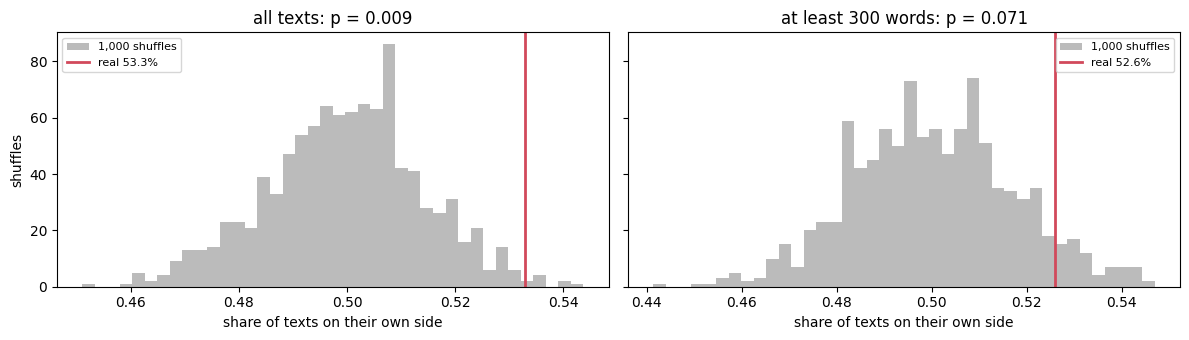

In [39]:
res7_all, null7_all = arrow_test(X, all_rows)
res7_long, null7_long = arrow_test(X, long_rows)
res7_ppmi, _ = arrow_test(D, all_rows)
res7_nostop, _ = arrow_test(D_nostop, all_rows)
step7 = pd.DataFrame([{'vectors': 'TF-IDF', 'texts used': 'all', **res7_all},
                      {'vectors': 'TF-IDF', 'texts used': 'at least 300 words', **res7_long},
                      {'vectors': 'PPMI', 'texts used': 'all', **res7_ppmi},
                      {'vectors': 'PPMI, no common neighbours (6d)', 'texts used': 'all', **res7_nostop}])
display(step7.style.hide(axis='index').format({'on own side': '{:.1%}', 'shuffled (average)': '{:.1%}', 'p (vs shuffled)': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, null, res, title in ((axes[0], null7_all, res7_all, 'all texts'),
                             (axes[1], null7_long, res7_long, 'at least 300 words')):
    ax.hist(null, bins=40, color='#bbbbbb', label='1,000 shuffles')
    ax.axvline(res['on own side'], color='#d1495b', lw=2, label=f"real {res['on own side']:.1%}")
    ax.set_title(f"{title}: p = {res['p (vs shuffled)']:.3f}")
    ax.set_xlabel('share of texts on their own side'); ax.legend(fontsize=8)
axes[0].set_ylabel('shuffles')
plt.tight_layout(); plt.show()

### 7. Niðurstøða

**With the arrow we see a small but real signal:** 53.3% of the texts lean towards the side the member voted, against 50.0% when the votes are shuffled. Only about 1 in 100 shuffles gets this high (p ≈ 0.01). With only the longer texts it is about the same (52.6%), but with fewer texts it is less certain (p ≈ 0.07).

**How to read it:** the lean is **weak**: about 3 texts in 100 more than chance. Many single debates do not show it (the work week: 45% on their own side). But across 133 debates, texts do lean a little towards their own side.

**With PPMI vectors the arrow does not work** (about 47% on their own side, no better than chance): the signal comes from TF-IDF.

**Why the arrow finds it and pairs (Step 4) did not:** a side does not have to *sound alike* to *lean the same way*.

**To check next:** the lean could come from the **party or bloc** (government vs opposition) rather than the vote itself.